In [1]:
!pip3 install numpy

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [2]:
!pip3 install matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [3]:
!pip3 install pandas

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [4]:
!pip3 install seaborn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [6]:
df=pd.read_csv('Diwali_Sales_Data.csv', encoding= 'unicode_escape')

In [7]:
df.shape

(11251, 15)

In [8]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  object 
 2   Product_ID        11251 non-null  object 
 3   Gender            11251 non-null  object 
 4   Age Group         11251 non-null  object 
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  object 
 8   Zone              11251 non-null  object 
 9   Occupation        11251 non-null  object 
 10  Product_Category  11251 non-null  object 
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), object(8)
memory usage: 1.3+ MB


In [10]:
#to drop the unwanted columns from the dataset
df.drop(['Status', 'unnamed1'], axis=1, inplace=True)

In [11]:
pd.isnull(df).sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [12]:
#drop the rows with null values
df.dropna(inplace=True)

In [13]:
#change the datatype of the column 'Amount' from object to int
df['Amount'] = df['Amount'].astype(int) 

In [14]:
df["Amount"].dtypes

dtype('int64')

In [15]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [16]:
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123900e+04,11239.000000,11239.000000,11239.000000,11239.000000
mean,1.003004e+06,35.410357,0.420055,2.489634,9453.610553
std,1.716039e+03,12.753866,0.493589,1.114967,5222.355168
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003064e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004426e+06,43.000000,1.000000,3.000000,12675.000000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


In [17]:
#use describe for specific columns
df[['Amount','Age']].describe()

,Amount,Age
count,11239.000000,11239.000000
mean,9453.610553,35.410357
std,5222.355168,12.753866
min,188.000000,12.000000
25%,5443.000000,27.000000
50%,8109.000000,33.000000
75%,12675.000000,43.000000
max,23952.000000,92.000000


### EDA

In [18]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

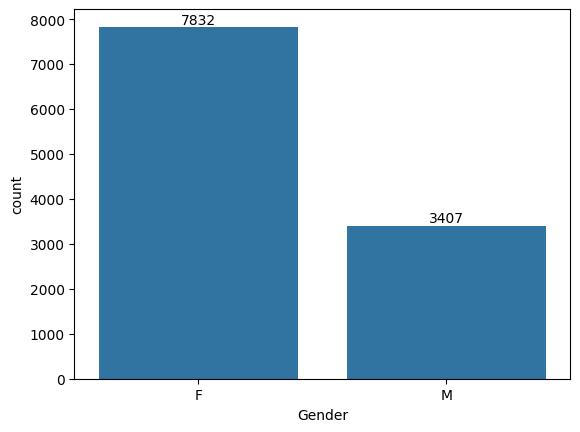

In [19]:
ax=sns.countplot(x='Gender', data=df)
#for showing the count of each bar on the top of the bar
for bars in ax.containers:
    ax.bar_label(bars)

In [20]:
df.groupby(['Gender'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

,Gender,Amount
0,F,74335853
1,M,31913276


<Axes: xlabel='Gender', ylabel='Amount'>

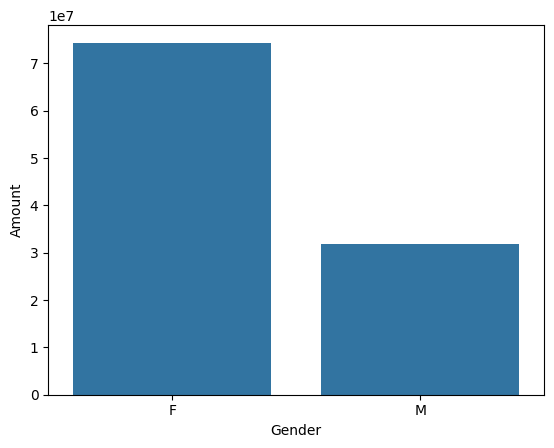

In [21]:
sales_gen=df.groupby(['Gender'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)
sns.barplot(x='Gender', y='Amount', data=sales_gen)

### Age


In [22]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

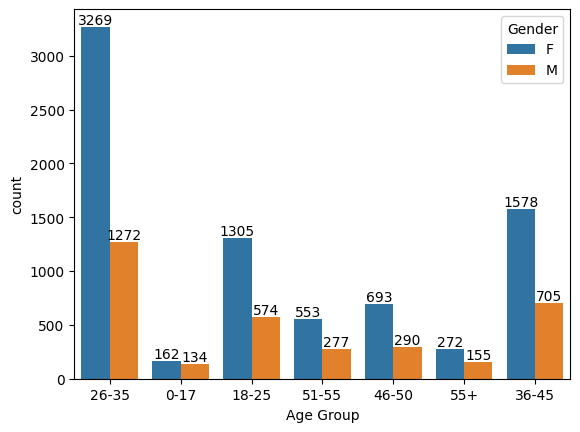

In [23]:
ax = sns.countplot(x='Age Group', data=df, hue='Gender')
for bars in ax.containers:
    ax.bar_label(bars)

###  Total Age Group wise sales

In [24]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [25]:
sales_age=df.groupby(['Age Group'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

<Axes: xlabel='Age Group', ylabel='Amount'>

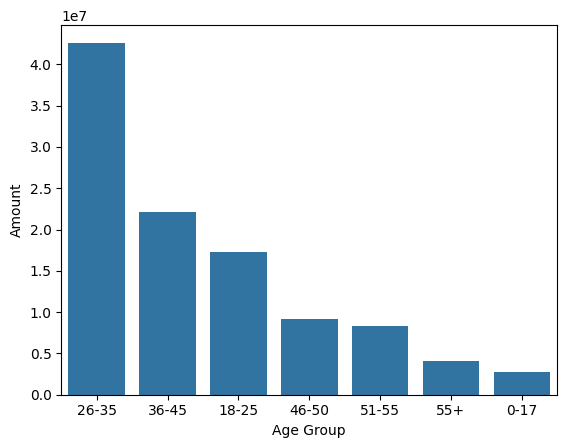

In [26]:
sns.barplot(x='Age Group', y='Amount', data=sales_age)

From above graph, most buyers are in age group of 26-35

### State

<Axes: xlabel='State', ylabel='Orders'>

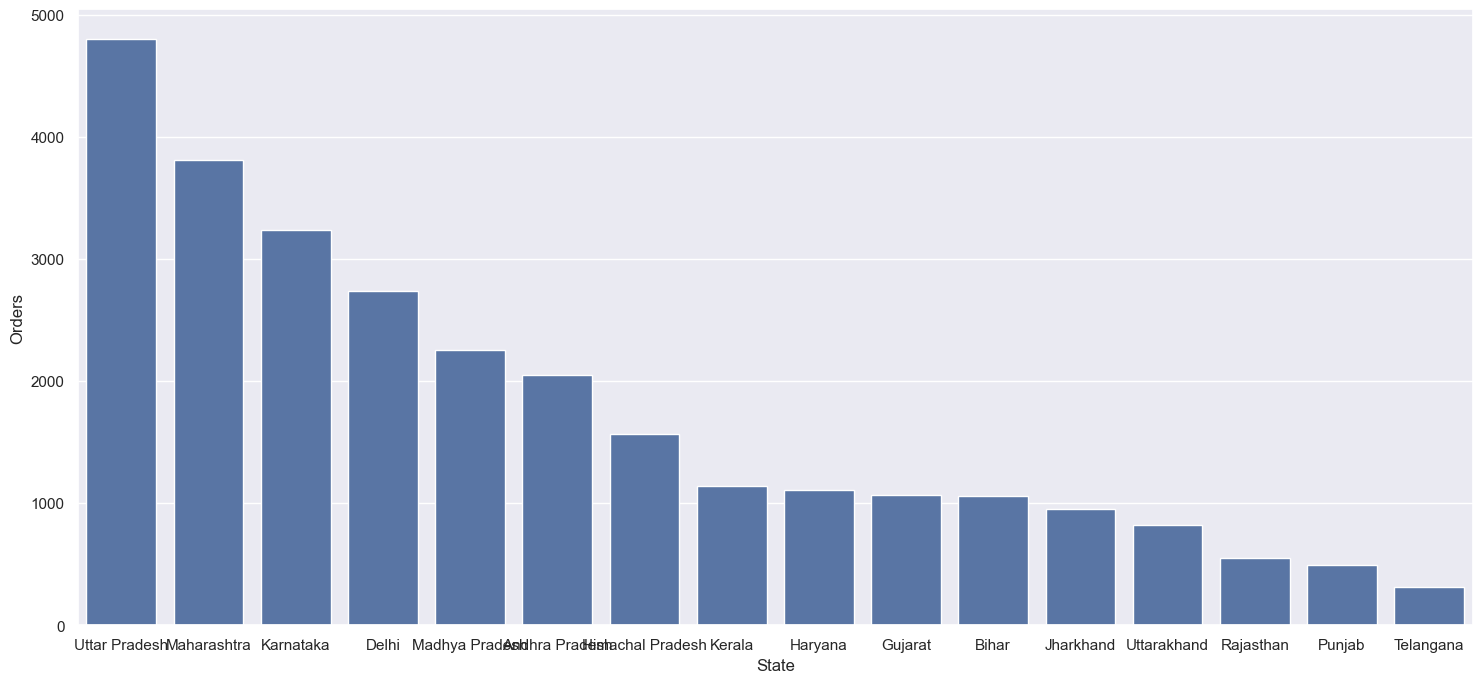

In [27]:
sales_state=df.groupby(['State'], as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False)
sns.set(rc={'figure.figsize':(18,8)})
sns.barplot(x='State', y='Orders', data=sales_state)

### Total amount/Sales from top 10 Sales Person

<Axes: xlabel='State', ylabel='Orders'>

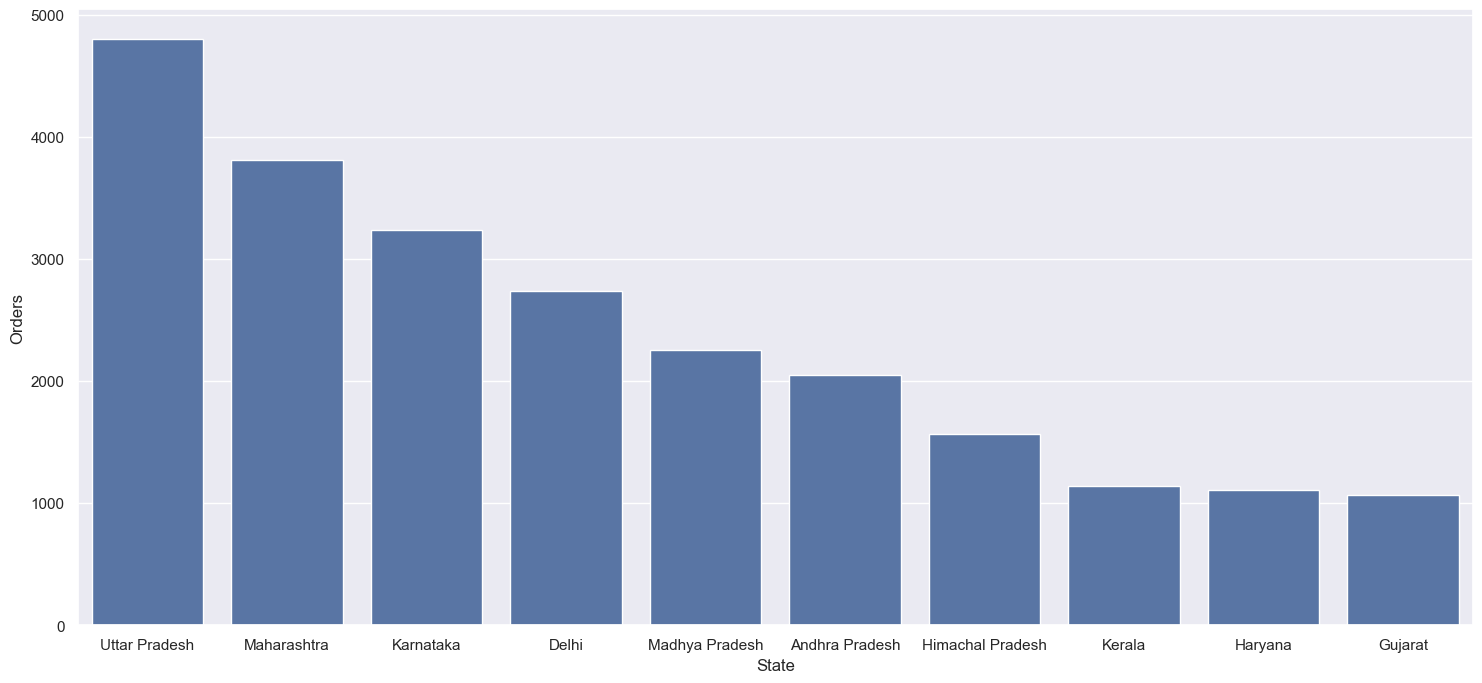

In [28]:
sales_state=df.groupby(['State'], as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)
sns.set(rc={'figure.figsize':(18,8)})
sns.barplot(x='State', y='Orders', data=sales_state)

<Axes: xlabel='State', ylabel='Amount'>

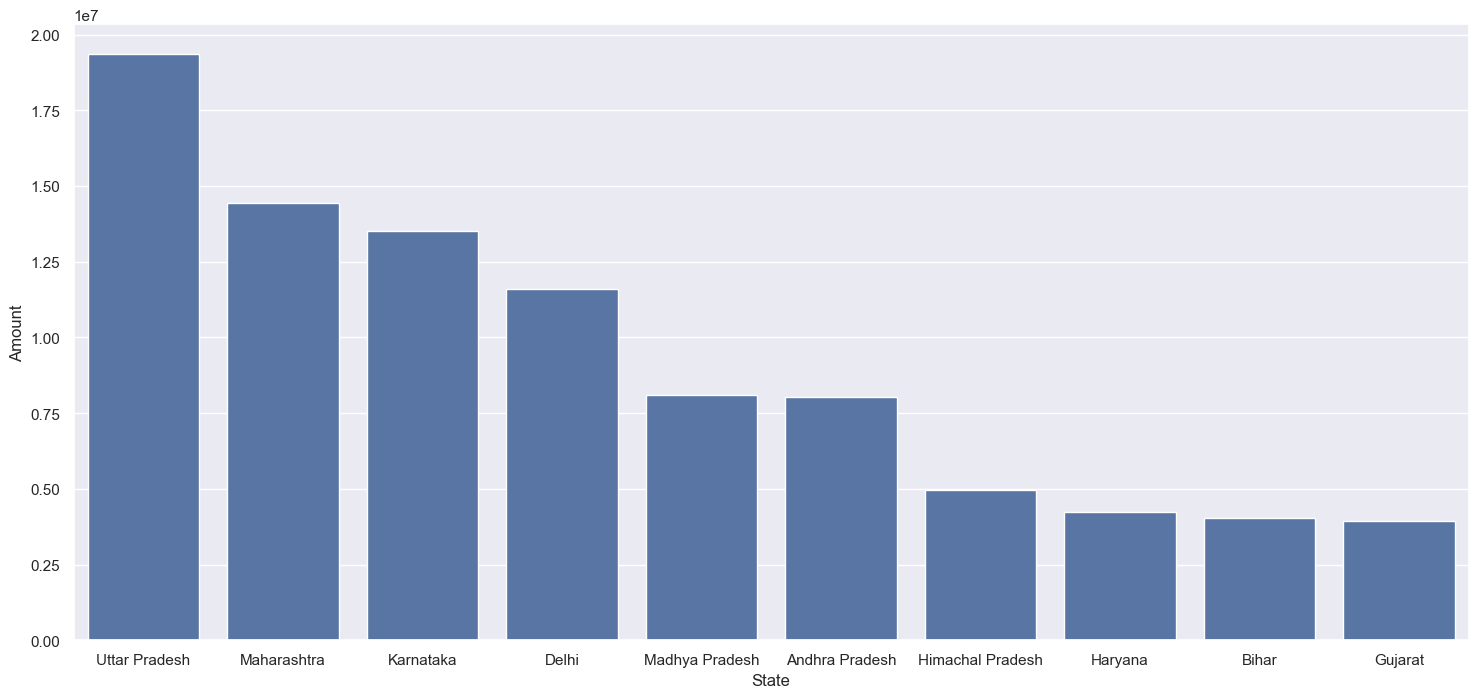

In [29]:
### Total amount/Sales from 10 states
sales_state=df.groupby(['State'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)
sns.set(rc={'figure.figsize':(18,8)})
sns.barplot(x='State', y='Amount', data=sales_state)

Most of the orders are from UP, Maharashtra, Karnatka

### Martial Status vs Sales


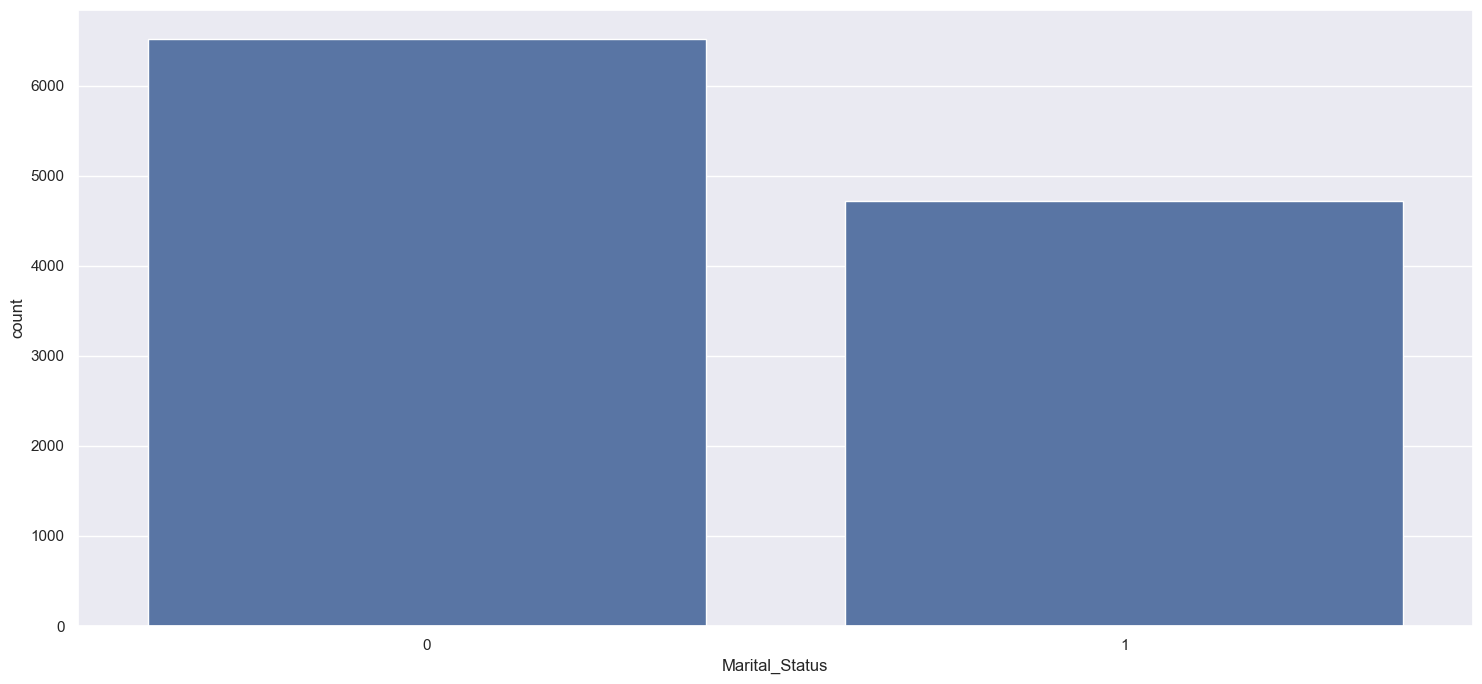

In [30]:
ax = sns.countplot(x='Marital_Status', data=df)

sns.set(rc={'figure.figsize':(18,8)})   
#for bars in ax.containers:
#    ax.bar_label(bars)

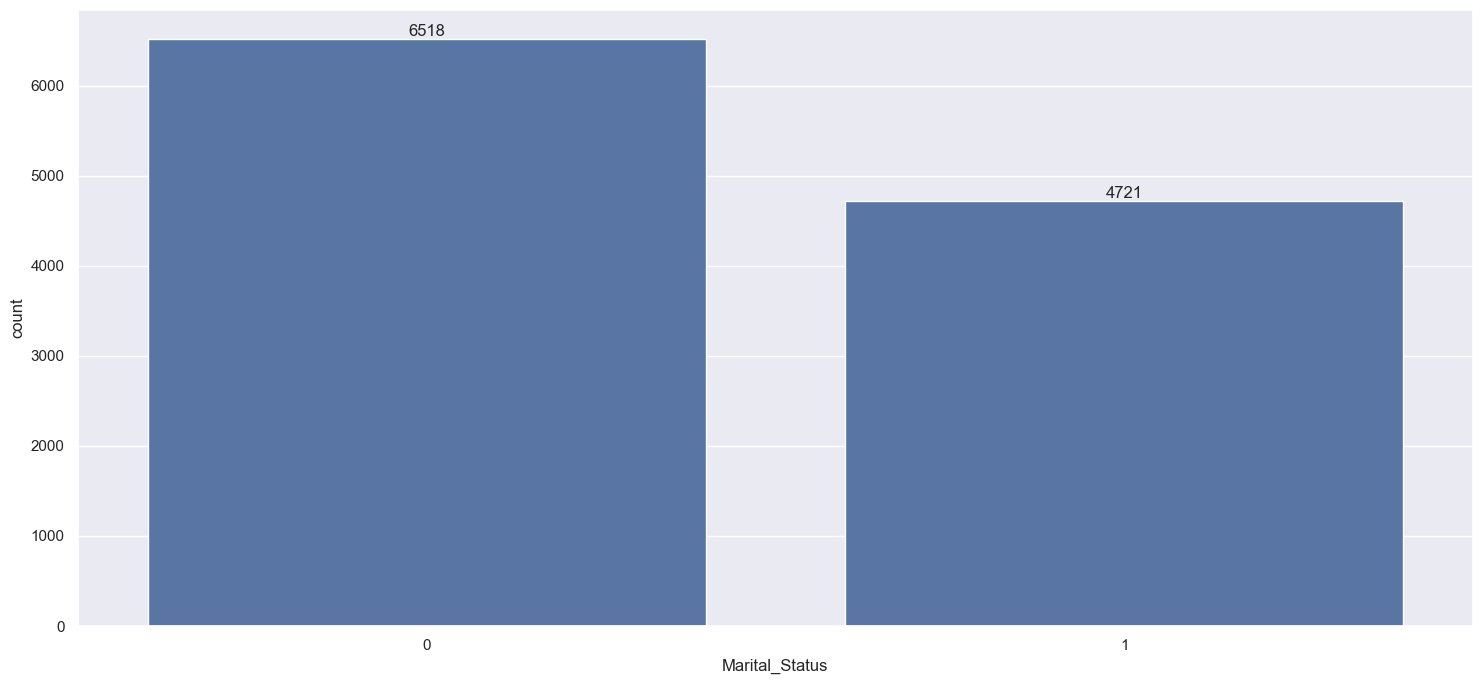

In [31]:
ax=sns.countplot(x='Marital_Status', data=df)
sns.set_theme(rc={'figure.figsize':(12,8)})  
for bars in ax.containers: 
    ax.bar_label(bars)

In [32]:
sales_state=df.groupby(['Marital_Status','Gender'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)
sns.set(rc={'figure.figsize':(18,8)})
sns.barplot(x='Marital_St###atus', y='Amount', data=sales_state,hue ='Gender')

ValueError: Could not interpret value `Marital_St###atus` for `x`. An entry with this name does not appear in `data`.

### Occupation

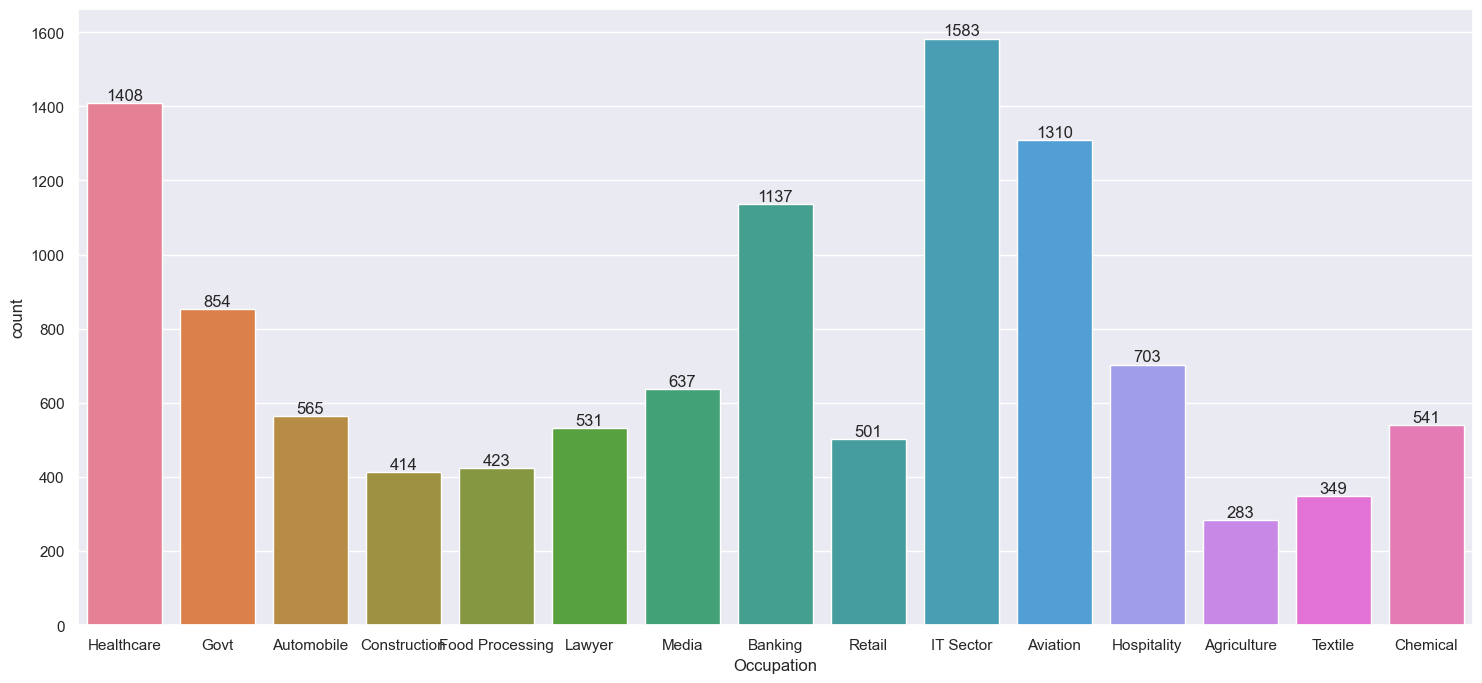

In [ ]:
sns.set_theme(rc={'figure.figsize':(18,8)})
ax=sns.countplot(x='Occupation', data=df,hue='Occupation')

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Occupation', ylabel='Amount'>

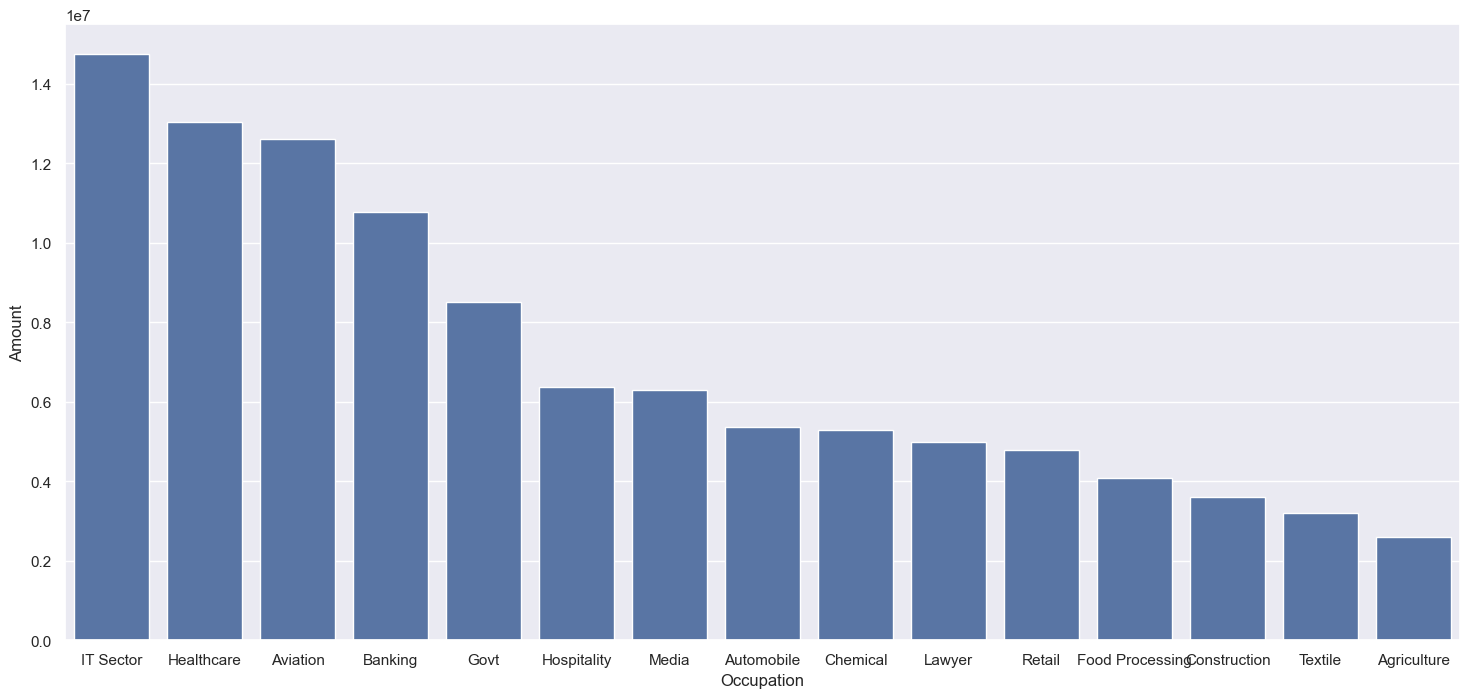

In [ ]:
sales_state=df.groupby(['Occupation'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)
sns.set(rc={'figure.figsize':(18,8)})
sns.barplot(x='Occupation', y='Amount', data=sales_state)

### Product Category

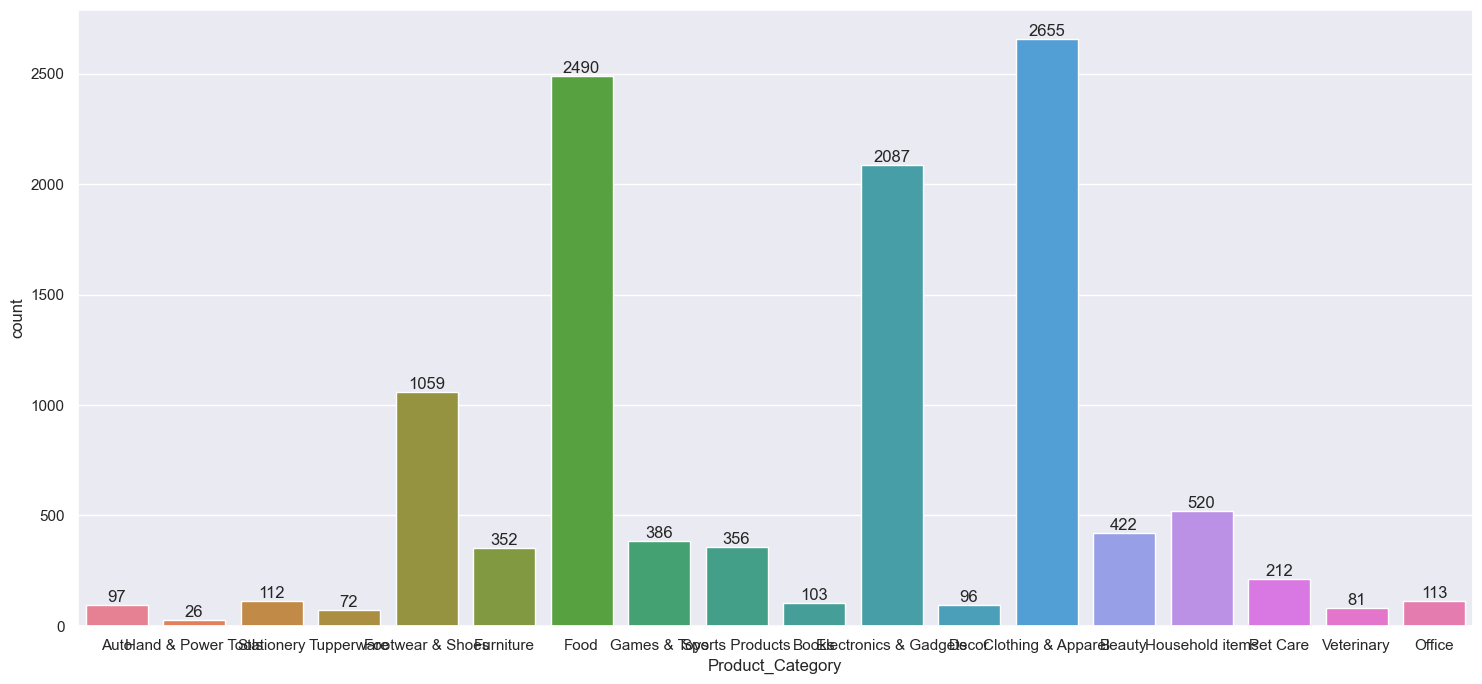

In [ ]:
sns.set_theme(rc={'figure.figsize':(18,8)})
ax=sns.countplot(x='Product_Category', data=df,hue='Product_Category')
for bars in ax.containers:
    ax.bar_label(bars)      

<Axes: xlabel='Product_Category', ylabel='Amount'>

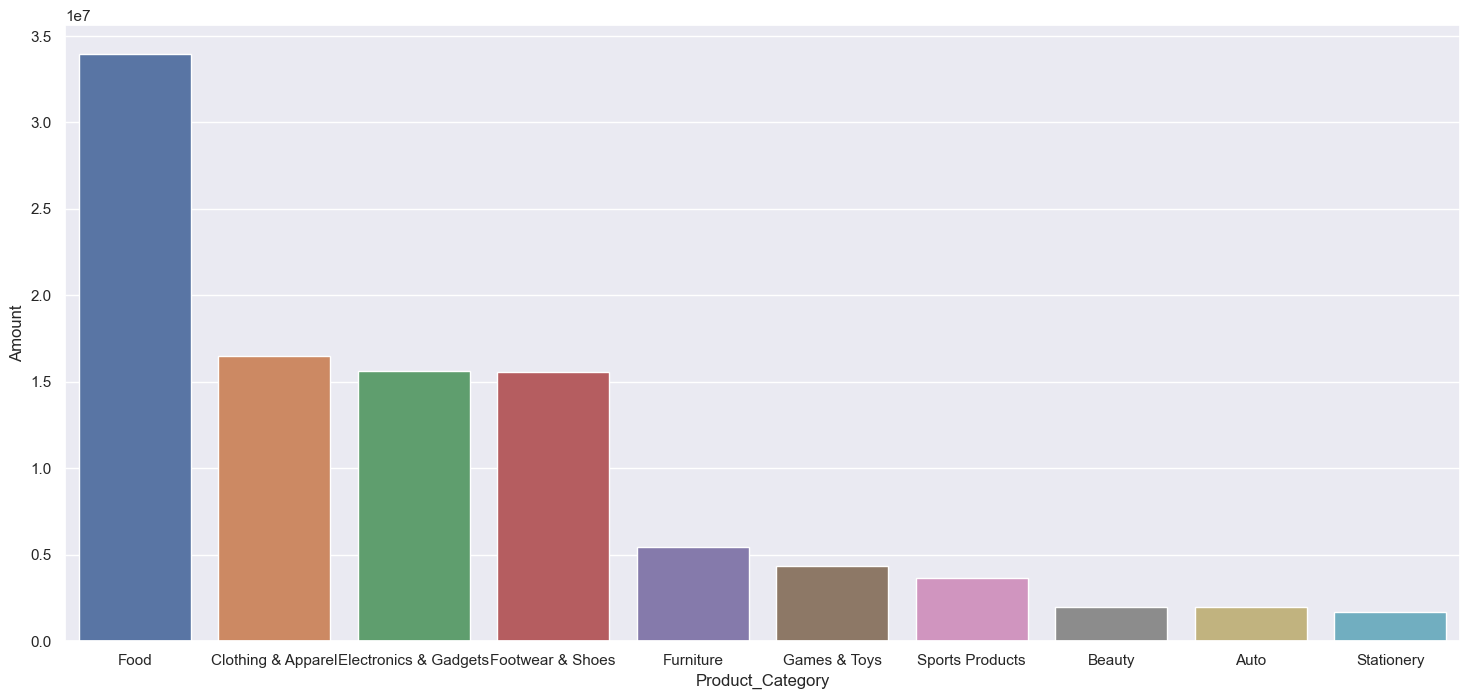

In [ ]:
sales_state=df.groupby(['Product_Category'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)
sns.set_theme(rc={'figure.figsize':(18,8)})   
sns.barplot(x='Product_Category', y='Amount', data=sales_state, hue='Product_Category')

Most sold products is food, clothing, Gadgets

In [ ]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

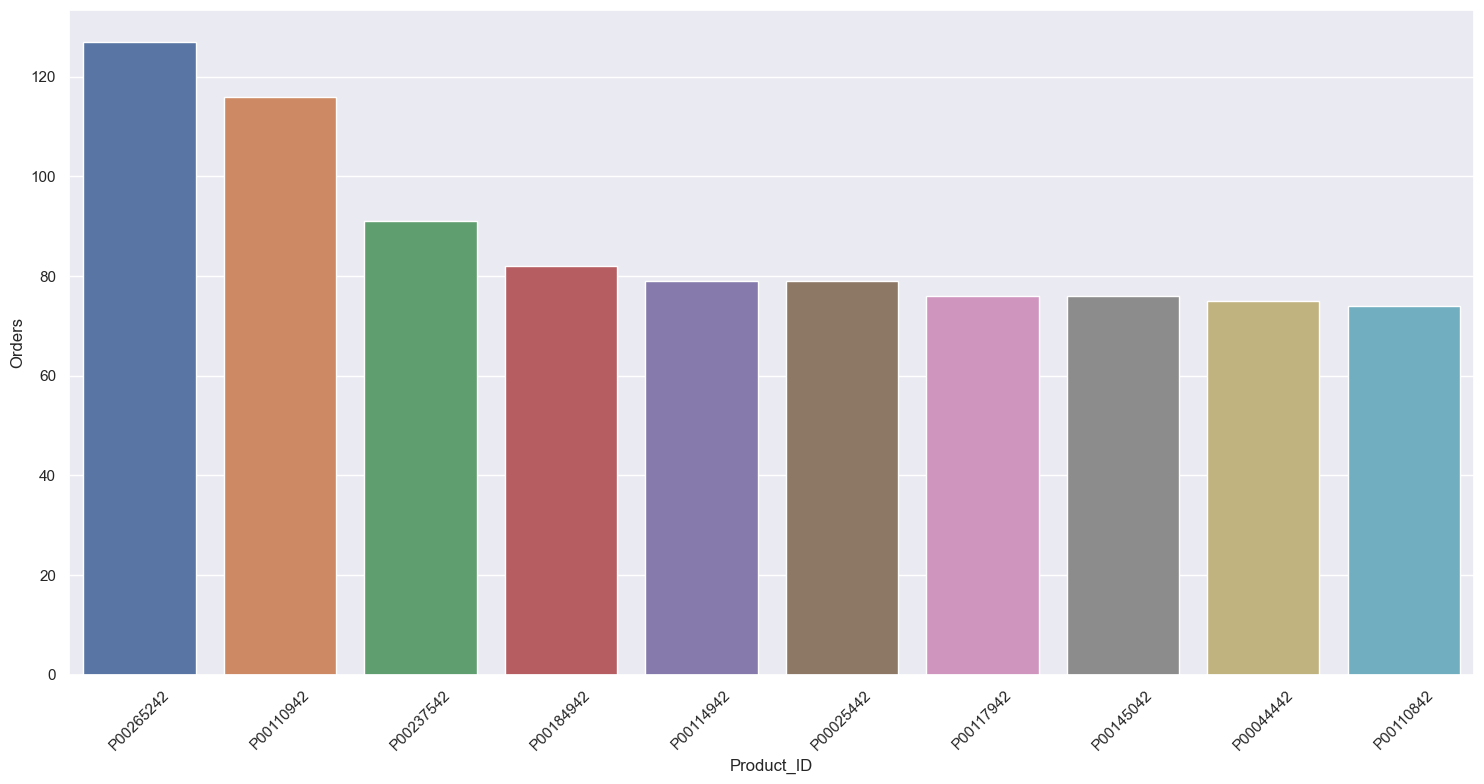

In [ ]:
sales_state = (
    df.groupby('Product_ID', as_index=False)['Orders']
      .sum()
      .sort_values(by='Orders', ascending=False)
      .head(10)
)

sns.set_theme(rc={'figure.figsize': (15, 8)})
sns.barplot(x='Product_ID', y='Orders', data=sales_state, hue='Product_ID', dodge=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
Conclusion:
1. The highest number of orders were placed by people in the age group of 26-35 years, followed by the age group of 36-45 years.
2. The highest number of orders were placed by married people, followed by single people.
3. The highest number of orders were placed by people with a professional occupation, followed by people with a student occupation.
4. The highest number of orders were placed by people from the state of Maharashtra, followed by people from the state of Karnataka.
5. The highest number of orders were placed for the product category of Electronics, followed by the product category of Clothing.
6. The highest number of orders were placed for the product ID of P002, followed by the product ID of P001.     